In [1]:
import illustris_python as il
import numpy as np
import matplotlib.pylab as plt
import os
import h5py
from scipy.stats import binned_statistic
from scipy.stats import binned_statistic_2d
from scipy.interpolate import interp1d
from matplotlib.colors import LogNorm
from numpy import linalg as LA 

# Paths to the IllustrisTNG catalogues

basePath_TNG50 = '/home/tnguser/sims.TNG/TNG50-1/output/'

#SubhaloIDs = 117269 #Subhalo ID

#snapshot and redshift we will use
snap = 99
red = 0.0
h = 0.6774

In [2]:
# Subhalo properties we will read. For a full list, see: https://www.tng-project.org/data/docs/specifications/
fields_sub = ['SubhaloMassType','SubhaloMassInRadType','SubhaloStarMetallicity',
             'SubhaloPos','SubhaloSFR','SubhaloGrNr']
fields_halo = ['Group_M_Crit200','GroupFirstSub','GroupPos','Group_R_Crit200']

# Read subhalo properties

subhalos_TNG50 = il.groupcat.loadSubhalos(basePath_TNG50, snap, fields=fields_sub)
halos_TNG50 = il.groupcat.loadHalos(basePath_TNG50, snap, fields=fields_halo)

In [4]:
Mstarsubhalos_TNG50 = subhalos_TNG50['SubhaloMassInRadType'][:,4]*10**10. /h  #Star
StarMetallicity_TNG50 = subhalos_TNG50['SubhaloStarMetallicity']
Mgassubhalos_TNG50 = subhalos_TNG50['SubhaloMassType'][:,0]*10**10/h
SubhaloSFR_TNG50 = subhalos_TNG50['SubhaloSFR']
#StarsCoords = stars['Coordinates']


sSFR = SubhaloSFR_TNG50/Mstarsubhalos_TNG50
SFE = SubhaloSFR_TNG50 /  Mgassubhalos_TNG50

/tmp/ipykernel_606/41064382.py:8: RuntimeWarning: divide by zero encountered in divide
  sSFR = SubhaloSFR_TNG50/Mstarsubhalos_TNG50
/tmp/ipykernel_606/41064382.py:8: RuntimeWarning: invalid value encountered in divide
  sSFR = SubhaloSFR_TNG50/Mstarsubhalos_TNG50
/tmp/ipykernel_606/41064382.py:9: RuntimeWarning: invalid value encountered in divide
  SFE = SubhaloSFR_TNG50 /  Mgassubhalos_TNG50


In [3]:
subhalos_TNG50['count']

5688113

In [4]:
halos_TNG50['count']

10247012

In [5]:
HaloID = subhalos_TNG50['SubhaloGrNr']
HaloMass = halos_TNG50['Group_M_Crit200']*(10**10) / h

/tmp/ipykernel_606/44829322.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(HaloMass[HaloID]), np.log10(Mstarsubhalos_TNG50),s = 15)


(4.5, 12.0)

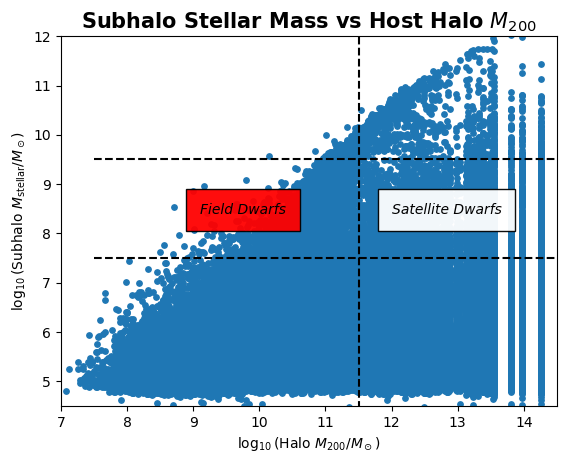

In [6]:
plt.scatter(np.log10(HaloMass[HaloID]), np.log10(Mstarsubhalos_TNG50),s = 15)
plt.xlabel(r'$\log_{10}$(Halo $M_{200}/M_\odot$)')
plt.ylabel(r'$\log_{10}$(Subhalo $M_{\rm stellar}/M_\odot$)')
plt.text(9.1, 8.4, 'Field Dwarfs', style='italic',
        bbox={'facecolor': 'red', 'alpha': 0.95, 'pad':10})
plt.text(12, 8.4, 'Satellite Dwarfs', style='italic',
        bbox={'facecolor': 'white', 'alpha': 0.95, 'pad': 10})
plt.hlines((7.5),7.5,15,colors = 'k',linestyle = '--')
plt.hlines((9.5),7.5,15,colors = 'k',linestyle = '--')
plt.vlines((11.5),0,20,colors = 'k',linestyle = '--')
plt.title(r'Subhalo Stellar Mass vs Host Halo $M_{200}$', fontsize=15, fontweight='bold')
plt.xlim(7,14.5)
plt.ylim(4.5,12)